In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

## Load Dataset

In [3]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()
print(X_train.shape, X_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(60000, 28, 28) (10000, 28, 28)


## Check Dataset

In [4]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (60000, 28, 28)
y_train shape: (60000,)
X_test shape: (10000, 28, 28)
y_test shape: (10000,)


## Processing

In [9]:
X_train = X_train.reshape(len(X_train), -1)
X_test = X_test.reshape(len(X_test), -1)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (48000, 784)
X_test: (10000, 784)


## Training & Validation Data

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Training label:", y_train.shape)
print("Validation label:", y_val.shape)

Training data: (38400, 784)
Validation data: (9600, 784)
Training label: (38400,)
Validation label: (9600,)


## Feature Standardization

In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [12]:
print("X_train_scaled:", X_train_scaled.shape)
print("X_val_scaled:", X_val_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)

X_train_scaled: (38400, 784)
X_val_scaled: (9600, 784)
X_test_scaled: (10000, 784)


In [13]:
input_dim = X_train.shape[1]
input_dim = X_train_scaled.shape[1]

print("Input dimension:", input_dim)

Input dimension: 784


## Model A (ReLU)

In [14]:
model_A = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(input_dim,)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model_A.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

## Model B (Tanh)

In [15]:
model_B = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(input_dim,)),
    tf.keras.layers.Dense(128, activation='tanh'),
    tf.keras.layers.Dense(64, activation='tanh'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model_B.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

## Model C (ReLU, deeper architecture)

In [16]:
model_C = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(input_dim,)),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model_C.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,762 (948.29 KB)

 Trainable params: 242,762 (948.29 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
models = {
    'Model A (ReLU)': model_A,
    'Model B (Tanh)': model_B,
    'Model C (Deep ReLU)': model_C
}

for model in models.values():
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

## Train models

In [18]:
import time

histories = {}
training_times = {}

for name, model in models.items():
    print(f"\nTraining {name}...")

    start_time = time.time()

    history = model.fit(
        X_train_scaled,
        y_train,
        validation_data=(X_val_scaled, y_val),
        epochs=15,
        batch_size=128,
        verbose=1
    )

    end_time = time.time()

    histories[name] = history
    training_times[name] = end_time - start_time

    print(f"{name} training time: {training_times[name]:.2f} seconds")


Training Model A (ReLU)...
Epoch 1/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.8964 - loss: 0.3493 - val_accuracy: 0.9456 - val_loss: 0.1799
Epoch 2/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9628 - loss: 0.1270 - val_accuracy: 0.9544 - val_loss: 0.1499
Epoch 3/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9754 - loss: 0.0814 - val_accuracy: 0.9617 - val_loss: 0.1338
Epoch 4/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9844 - loss: 0.0553 - val_accuracy: 0.9631 - val_loss: 0.1254
Epoch 5/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9902 - loss: 0.0364 - val_accuracy: 0.9625 - val_loss: 0.1349
Epoch 6/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9929 - loss: 0.0260 - val_accuracy: 0.9650 - val_loss: 0.1283
Epoch 7/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.9958 - loss: 0.0171 - val_accuracy: 0.9654 - val_loss: 0.1346
Epoch 8/15
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9969 - 

## Acuracy Conparison

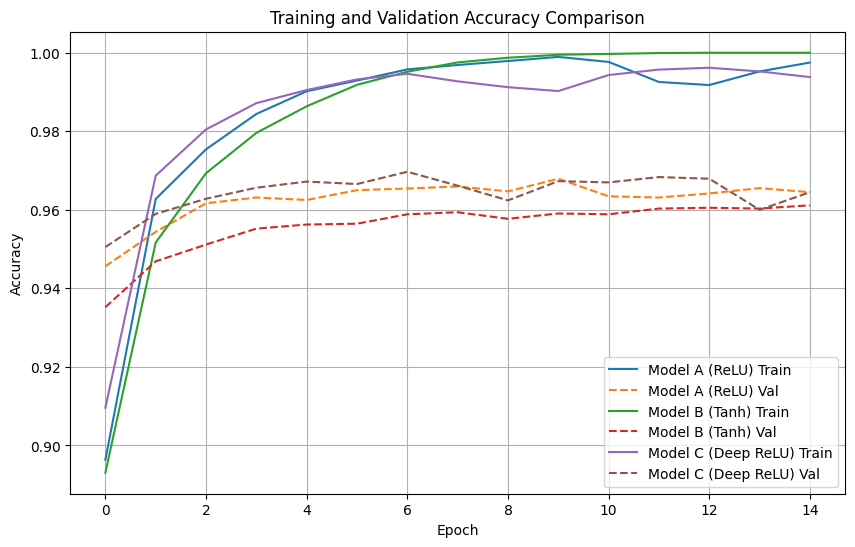

In [19]:
plt.figure(figsize=(10, 6))

for name, history in histories.items():
    plt.plot(history.history['accuracy'], label=f'{name} Train')
    plt.plot(history.history['val_accuracy'], linestyle='--', label=f'{name} Val')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy Comparison')
plt.legend()
plt.grid()
plt.show()

## Evalation

In [20]:
results = {}

for name, model in models.items():
    test_loss, test_accuracy = model.evaluate(
        X_test_scaled,
        y_test,
        verbose=0
    )

    results[name] = {
        'Test Loss': test_loss,
        'Test Accuracy': test_accuracy,
        'Training Time (s)': training_times[name]
    }

    print(f"{name}")
    print(f"Test Loss: {test_loss:.4f}")
    print(f"Test Accuracy: {test_accuracy:.4f}")
    print("-" * 30)

Model A (ReLU)
Test Loss: 36.2639
Test Accuracy: 0.9134
------------------------------
Model B (Tanh)
Test Loss: 0.4200
Test Accuracy: 0.8919
------------------------------
Model C (Deep ReLU)
Test Loss: 36.7789
Test Accuracy: 0.9200
------------------------------


- Model A: accuracy cukup baik sebesar 91.34%.
- Model B: memiliki accuracy terendah, yaitu 89.19%, tetapi test loss jauh lebih rendah.
- Model C: menghasilkan accuracy tertinggi sebesar 92.00%, tetapi test loss-nya sangat tinggi.
Model C meningkatkan accuracy sebesar 0.66 percentage points dibanding Model A, dan 2.81 percentage points dibanding Model B.
Ini hal yang perlu kita investigasi. Accuracy Model A dan C cukup bagus, tetapi loss-nya mencapai 36, padahal Model B hanya 0.42.

Hal ini bisa terjadi karena accuracy dan loss mengukur hal yang berbeda.
- Accuracy hanya melihat apakah prediksi kelasnya benar atau salah.
- Loss juga memperhitungkan seberapa yakin model terhadap prediksinya.

In [29]:
model_names = list(models.keys())
model_list = list(models.values())

acc_list = [
    results[name]['Test Accuracy']
    for name in model_names
]

best_idx = acc_list.index(max(acc_list))
best_model = model_list[best_idx]
best_model_name = model_names[best_idx]

print("Best Model:", best_model_name)
print("Best Accuracy:", acc_list[best_idx])

y_pred_prob = best_model.predict(X_test_scaled, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)

Best Model: Model C (Deep ReLU)
Best Accuracy: 0.9200000166893005


In [30]:
from sklearn.metrics import classification_report, confusion_matrix

print("Best Model:", best_model_name)
print("\nClassification Report:\n")

print(classification_report(y_test, y_pred))

Best Model: Model C (Deep ReLU)

Classification Report:

              precision    recall  f1-score   support

           0       0.98      0.91      0.94       980
           1       0.96      0.99      0.97      1135
           2       0.92      0.96      0.94      1032
           3       0.77      1.00      0.87      1010
           4       0.97      0.94      0.96       982
           5       0.97      0.74      0.84       892
           6       0.97      0.95      0.96       958
           7       0.98      0.89      0.93      1028
           8       0.82      0.93      0.87       974
           9       0.94      0.87      0.90      1009

    accuracy                           0.92     10000
   macro avg       0.93      0.92      0.92     10000
weighted avg       0.93      0.92      0.92     10000



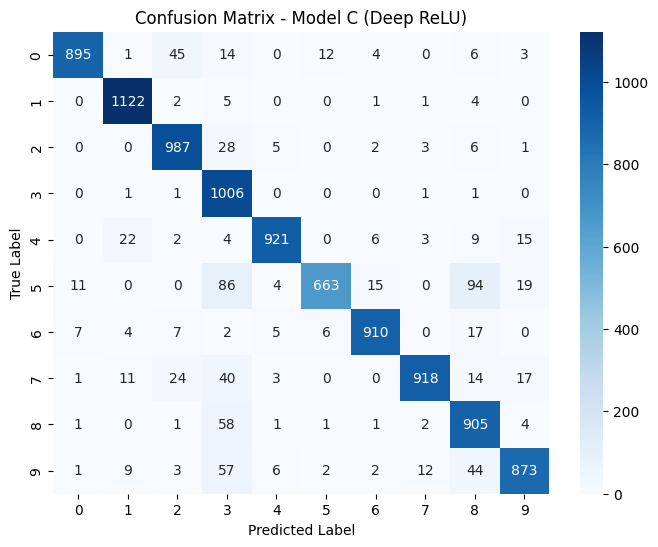

In [31]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title(f'Confusion Matrix - {best_model_name}')

plt.show()

The best model was selected based on the highest test accuracy among the three ANN models. The classification report was used to evaluate precision, recall, and F1-score for each digit. The confusion matrix was used to identify digits that were frequently misclassified. Overall, the evaluation helps determine how well the model recognizes handwritten digits and which classes remain challenging.